# 포켓몬 영문 도감 설명의 텍스트 마이닝: 타입 예측과 세대별 문체 변화

- **RQ1.** 도감 설명의 영어 어휘는 포켓몬의 타입을 반영하는가?
- **RQ2.** 도감 설명의 문체(설명 길이, 문장 길이, 품사 비율)는 설명이 처음 쓰인 게임 세대(1~9세대)에 따라 달라지는가?


In [2]:
### 1단계. 환경 설정. 필요한 패키지 설치 (Colab / 로컬 자동 구분) ###
import os, sys

IN_COLAB = "google.colab" in sys.modules
print("Colab 환경 여부:", IN_COLAB)

# 필요한 패키지 설치 (selenium 버전은 수업 예제와 동일)
%pip install -q selenium==4.25.0 webdriver-manager==4.0.2 nltk scikit-learn scipy pandas matplotlib seaborn

# Colab에서만 Chrome을 직접 설치 (로컬에는 Chrome이 이미 설치되어 있다고 가정)
if IN_COLAB:
    os.system("apt-get purge -y chromium-browser chromium-chromedriver > /dev/null 2>&1")
    os.system("wget -q https://dl.google.com/linux/direct/google-chrome-stable_current_amd64.deb")
    os.system("apt-get install -y ./google-chrome-stable_current_amd64.deb > /dev/null 2>&1")
    print("Chrome 설치 완료")

Colab 환경 여부: False

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


✅ 접속 성공 → Pokémon Pokédex: list of Pokémon with stats | Pokémon Database


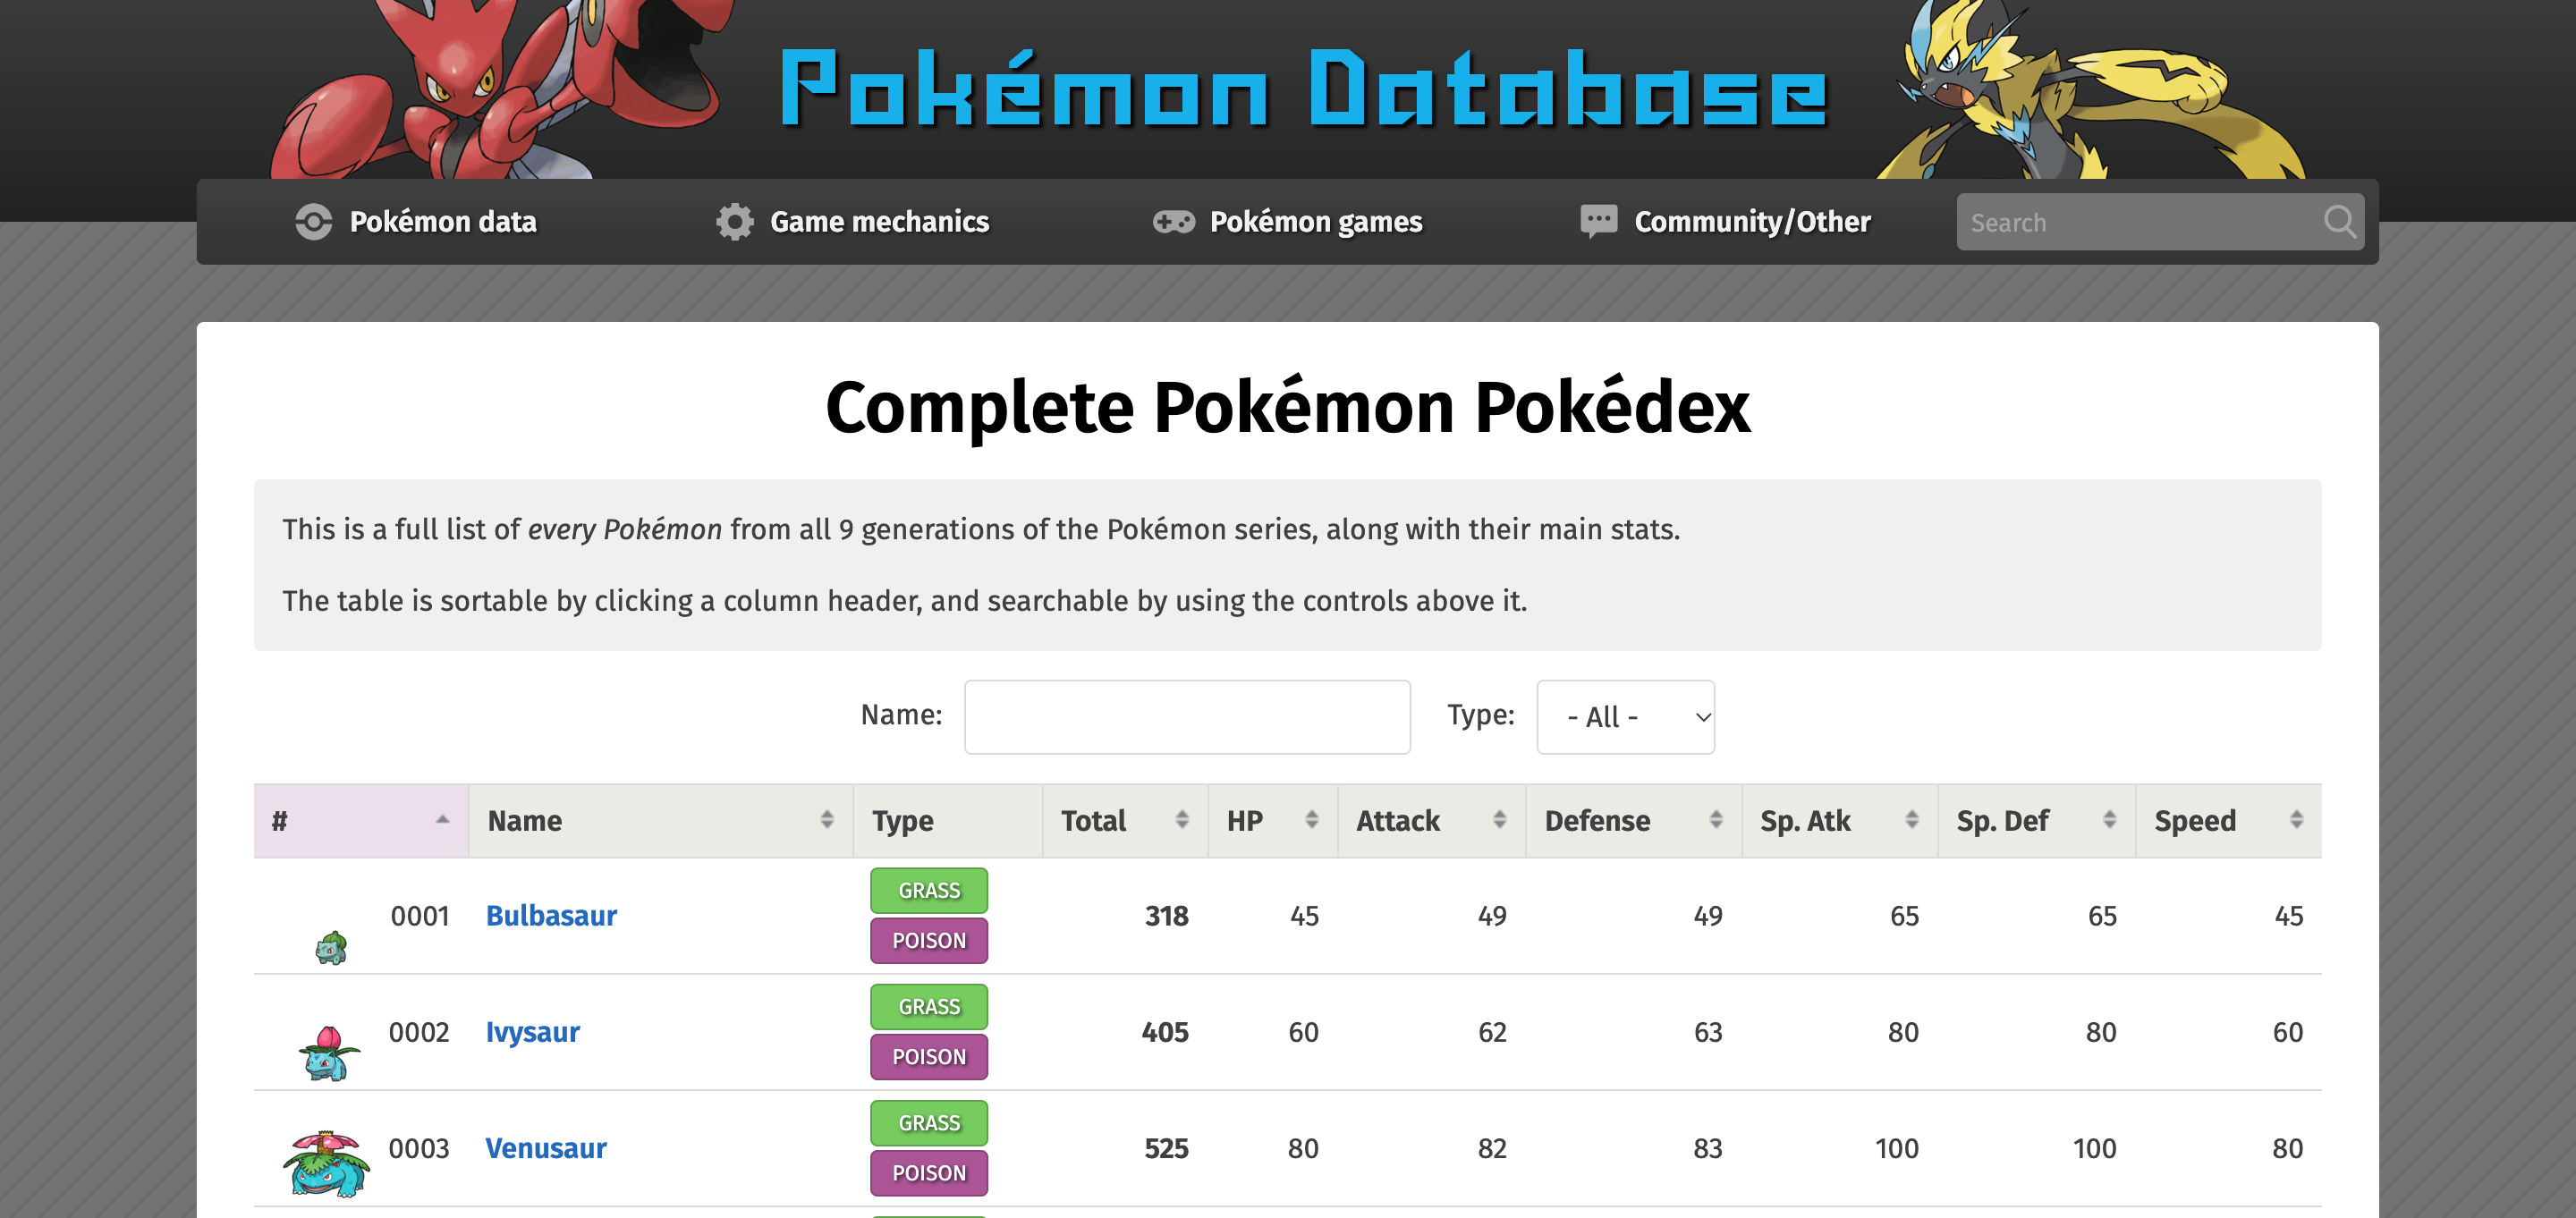

In [1]:
### 2단계. 라이브러리 불러오기 및 WebDriver 설정. 크롬 드라이버를 만들고 도감 전체 목록 페이지를 연다 ###
import os, re, time
import numpy as np
import pandas as pd
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.chrome.options import Options
from webdriver_manager.chrome import ChromeDriverManager

options = Options()
#options.add_argument("--headless=new") ## 주석처리 하면 크롤링 과정을 눈으로 볼 수 있음
options.add_argument("--no-sandbox")
options.add_argument("--disable-dev-shm-usage")
options.add_argument("--window-size=1920,1080")
options.add_argument("user-agent=Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0 Safari/537.36")
options.page_load_strategy = "eager"   # 페이지가 다 로딩되길 기다리지 않고 빠르게 진행

service = Service(ChromeDriverManager().install())
driver = webdriver.Chrome(service=service, options=options)

driver.get("https://pokemondb.net/pokedex/all")
print("✅ 접속 성공 →", driver.title)

from IPython.display import Image, display
driver.save_screenshot("check.png")
display(Image("check.png"))

In [2]:
### 3단계. 도감 전체 표 크롤링. pokemondb 표에서 번호, 이름, 타입, 능력치를 수집한다 ###
rows = driver.find_elements(By.XPATH, '//table[@id="pokedex"]/tbody/tr')
if len(rows) == 0:   # id가 다를 경우를 대비한 예비 경로
    rows = driver.find_elements(By.XPATH, "//table/tbody/tr")
print("표의 행 수:", len(rows))

data = []
for i, row in enumerate(rows):
    tds = row.find_elements(By.TAG_NAME, "td")
    link = tds[1].find_element(By.TAG_NAME, "a")
    types = tds[2].text.split()

    data.append({
        "Dex_Num": int(tds[0].text.strip()),
        "Name": link.text.strip(),
        "URL_Name": link.get_attribute("href").split("/")[4],   # 상세 페이지 주소에 쓰는 이름
        "Type1": types[0],
        "Type2": types[1] if len(types) > 1 else "",
        "Total": int(tds[3].text),
        "HP": int(tds[4].text),
        "Attack": int(tds[5].text),
        "Defense": int(tds[6].text),
        "Sp_Atk": int(tds[7].text),
        "Sp_Def": int(tds[8].text),
        "Speed": int(tds[9].text),
    })
    if (i + 1) % 300 == 0:
        print(i + 1, "행 수집 중...")

pokemon_all = pd.DataFrame(data)
pokemon_all.to_csv("pokemon_all.csv", index=False, encoding="utf-8-sig")
print(pokemon_all.shape)
pokemon_all.head()

표의 행 수: 1261
300 행 수집 중...
600 행 수집 중...
900 행 수집 중...
1200 행 수집 중...
(1261, 12)


,Dex_Num,Name,URL_Name,Type1,Type2,Total,HP,Attack,Defense,Sp_Atk,Sp_Def,Speed
0,1,Bulbasaur,bulbasaur,GRASS,POISON,318,45,49,49,65,65,45
1,2,Ivysaur,ivysaur,GRASS,POISON,405,60,62,63,80,80,60
2,3,Venusaur,venusaur,GRASS,POISON,525,80,82,83,100,100,80
3,3,Venusaur,venusaur,GRASS,POISON,625,80,100,123,122,120,80
4,4,Charmander,charmander,FIRE,,309,39,52,43,60,50,65


In [3]:
### 4단계. 종(Species)별 정리. 메가진화/리전폼 등 중복 행을 Dex_Num 기준으로 1개만 남긴다 ###
# 표는 같은 번호의 기본 폼이 가장 먼저 나오므로 keep="first"
pokemon = pokemon_all.drop_duplicates(subset="Dex_Num", keep="first").reset_index(drop=True)
pokemon.to_csv("pokemon.csv", index=False, encoding="utf-8-sig")

print("전체 행:", len(pokemon_all), "→ 종 기준:", len(pokemon))
print(pokemon["Type1"].value_counts())
pokemon.head()

전체 행: 1261 → 종 기준: 1025
Type1
WATER       134
NORMAL      118
GRASS       103
BUG          83
FIRE         66
PSYCHIC      60
ELECTRIC     59
ROCK         58
DARK         45
POISON       42
GROUND       40
FIGHTING     40
DRAGON       37
STEEL        36
GHOST        35
ICE          31
FAIRY        29
FLYING        9
Name: count, dtype: int64


,Dex_Num,Name,URL_Name,Type1,Type2,Total,HP,Attack,Defense,Sp_Atk,Sp_Def,Speed
0,1,Bulbasaur,bulbasaur,GRASS,POISON,318,45,49,49,65,65,45
1,2,Ivysaur,ivysaur,GRASS,POISON,405,60,62,63,80,80,60
2,3,Venusaur,venusaur,GRASS,POISON,525,80,82,83,100,100,80
3,4,Charmander,charmander,FIRE,,309,39,52,43,60,50,65
4,5,Charmeleon,charmeleon,FIRE,,405,58,64,58,80,65,80


In [ ]:
### 5단계. 상세 페이지 크롤링. 종마다 영문 도감 설명(Pokédex entries)을 모두 수집한다 ###
# (종 약 1,000개 × 1초 대기 → 30~40분 정도 걸림. 중간에 멈춰도 다시 실행하면 이어서 진행됨)
LIMIT = None   # 테스트할 때는 30 처럼 숫자로 바꿔서 실행. 전체 수집은 None
SAVE_FILE = "pokemon_entries_raw.csv"

if os.path.exists(SAVE_FILE):
    saved = pd.read_csv(SAVE_FILE, keep_default_na=False)
    entry_rows = saved.to_dict("records")
    done = set(saved["Dex_Num"])
    print("이어서 진행:", len(done), "종 완료")
else:
    entry_rows = []
    done = set()

targets = pokemon if LIMIT is None else pokemon.head(LIMIT)

for i, row in targets.iterrows():
    dex = row["Dex_Num"]
    if dex in done:
        continue

    url = "https://pokemondb.net/pokedex/" + row["URL_Name"]
    try:
        driver.get(url)
        # 'Pokédex entries' 제목 바로 아래 표의 모든 줄을 가져온다
        trs = driver.find_elements(By.XPATH, '//h2[contains(., "entries")]/following::table[1]//tr')

        count = 0
        for tr in trs:
            cells = tr.find_elements(By.XPATH, "./th | ./td")
            if len(cells) < 2:
                continue
            games = cells[0].text.split("\n")   # 예: ["Red", "Blue"]
            text = cells[1].text.strip()
            if text == "":
                continue
            entry_rows.append({"Dex_Num": dex, "Name": row["Name"],
                               "Games": " | ".join(games), "Text": text})
            count += 1

        if count == 0:   # 설명이 없는 종도 '완료'로 표시
            entry_rows.append({"Dex_Num": dex, "Name": row["Name"], "Games": "", "Text": ""})

    except Exception as e:
        print("오류:", row["Name"], e)
        driver.save_screenshot("error_" + row["Name"] + ".png")
        continue   # 완료 목록에 넣지 않으므로 다시 실행하면 재시도됨

    done.add(dex)
    print(dex, row["Name"], count)
    time.sleep(1)   # 사이트에 부담을 주지 않도록 1초 쉬기

    if len(done) % 50 == 0:
        pd.DataFrame(entry_rows).to_csv(SAVE_FILE, index=False, encoding="utf-8-sig")
        print(len(done), "종 수집 완료 (중간 저장)")

pd.DataFrame(entry_rows).to_csv(SAVE_FILE, index=False, encoding="utf-8-sig")
print("✅ 크롤링 끝:", len(done), "종,", len(entry_rows), "개 설명")

1 Bulbasaur 19
2 Ivysaur 20
3 Venusaur 20
4 Charmander 20
5 Charmeleon 20
6 Charizard 20
7 Squirtle 21
8 Wartortle 20
9 Blastoise 20
10 Caterpie 24
11 Metapod 24
12 Butterfree 24
13 Weedle 18
14 Kakuna 18
15 Beedrill 18
16 Pidgey 18
17 Pidgeotto 18
18 Pidgeot 18
19 Rattata 23
20 Raticate 23
21 Spearow 22
22 Fearow 23
23 Ekans 20
24 Arbok 20
25 Pikachu 32
26 Raichu 32
27 Sandshrew 27
28 Sandslash 27
29 Nidoran♀ 20
30 Nidorina 20
✅ 크롤링 끝: 30 종, 649 개 설명


In [5]:
### 6단계. 크롤링 마무리 및 원본 데이터 확인. 브라우저를 닫고 수집 결과를 확인한다 ###
driver.quit()

raw = pd.read_csv("pokemon_entries_raw.csv", keep_default_na=False)
raw = raw[raw["Text"] != ""]
print("수집된 설명 수:", len(raw), "/ 설명이 있는 종:", raw["Dex_Num"].nunique())
raw.head(10)

수집된 설명 수: 649 / 설명이 있는 종: 30


,Dex_Num,Name,Games,Text
0,1,Bulbasaur,Red | Blue,A strange seed was planted on its back at birt...
1,1,Bulbasaur,Yellow,It can go for days without eating a single mor...
2,1,Bulbasaur,Gold,The seed on its back is filled with nutrients....
3,1,Bulbasaur,Silver,It carries a seed on its back right from birth...
4,1,Bulbasaur,Crystal,"While it is young, it uses the nutrients that ..."
5,1,Bulbasaur,Ruby | Sapphire | Emerald,BULBASAUR can be seen napping in bright sunlig...
6,1,Bulbasaur,FireRed,There is a plant seed on its back right from t...
7,1,Bulbasaur,LeafGreen,A strange seed was planted on its back at birt...
8,1,Bulbasaur,Diamond | Pearl | Platinum,"For some time after its birth, it grows by gai..."
9,1,Bulbasaur,HeartGold,The seed on its back is filled with nutrients....


In [6]:
### 7단계. 데이터 불러오기 및 세대 라벨링. 게임 이름을 세대로 바꾸고, 같은 문장이 여러 게임에 반복된 경우 처음 쓰인 세대만 남긴다 ###
# (크롤링을 이미 끝냈다면 여기부터 실행해도 됨)
pokemon = pd.read_csv("pokemon.csv")
raw = pd.read_csv("pokemon_entries_raw.csv", keep_default_na=False)
raw = raw[raw["Text"] != ""].copy()

GAME_GEN = {
    "Red": 1, "Blue": 1, "Yellow": 1,
    "Gold": 2, "Silver": 2, "Crystal": 2,
    "Ruby": 3, "Sapphire": 3, "Emerald": 3, "FireRed": 3, "LeafGreen": 3,
    "Diamond": 4, "Pearl": 4, "Platinum": 4, "HeartGold": 4, "SoulSilver": 4,
    "Black": 5, "White": 5, "Black 2": 5, "White 2": 5,
    "X": 6, "Y": 6, "Omega Ruby": 6, "Alpha Sapphire": 6,
    "Sun": 7, "Moon": 7, "Ultra Sun": 7, "Ultra Moon": 7,
    "Let's Go Pikachu": 7, "Let's Go Eevee": 7,
    "Sword": 8, "Shield": 8, "Brilliant Diamond": 8, "Shining Pearl": 8, "Legends: Arceus": 8,
    "Scarlet": 9, "Violet": 9, "Legends: Z-A": 9,
}

def find_gen(games_text):
    gens = []
    for g in games_text.split(" | "):
        g = g.replace("’", "'").strip()
        if g in GAME_GEN:
            gens.append(GAME_GEN[g])
    if len(gens) == 0:
        return None
    return min(gens)

raw["Gen"] = raw["Games"].apply(find_gen)
print("세대를 알 수 없는 게임(있다면 GAME_GEN에 추가):", raw[raw["Gen"].isna()]["Games"].unique())

entries = raw.dropna(subset=["Gen"]).copy()
entries["Gen"] = entries["Gen"].astype(int)

# 같은 종에서 문장이 똑같은 경우(리메이크 등)는 가장 먼저 나온 세대 하나만 남긴다
entries = entries.sort_values(["Dex_Num", "Gen"])
entries = entries.drop_duplicates(subset=["Dex_Num", "Text"], keep="first").reset_index(drop=True)

print("중복 제거 전:", len(raw), "→ 후:", len(entries))
print(entries["Gen"].value_counts().sort_index())

세대를 알 수 없는 게임(있다면 GAME_GEN에 추가): <StringArray>
[]
Length: 0, dtype: str
중복 제거 전: 649 → 후: 450
Gen
1     60
2     90
3    109
4     42
5     10
6     49
7     60
8     29
9      1
Name: count, dtype: int64


In [8]:
### 8단계. NLTK 준비 및 전처리 함수. 정규표현식 정제, 토큰화, 포켓몬 이름 제거, 품사 태깅, 표제어 추출을 한 번에 하는 함수를 만든다 ###
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import ssl

try:
    ssl._create_default_https_context = ssl._create_unverified_context   # 맥 SSL 인증서 오류 우회
except AttributeError:
    pass

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    ok = nltk.download(pkg, quiet=True)
    print(pkg, "→", ok)   # False면 다운로드 실패

stop_words = set(stopwords.words("english"))
stop_words.add("pokemon")          # 모든 설명에 나오는 단어라 분석에 도움이 안 됨
lemmatizer = WordNetLemmatizer()

# 포켓몬 이름은 단어 하나짜리만 제거 대상으로 사용 (Mr. Mime 같은 이름은 제외)
name_set = set()
for name in pokemon["Name"]:
    if re.fullmatch(r"[A-Za-zé]+", name):
        name_set.add(name.lower().replace("é", "e"))
print("제거할 포켓몬 이름 수:", len(name_set))

def get_wordnet_pos(tag):
    # 품사 태그 → 표제어 추출용 품사 (형용사 a, 동사 v, 부사 r, 나머지는 명사 n)
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("R"):
        return "r"
    return "n"

def process_text(text):
    n_sent = len(sent_tokenize(text))                  # 문장 수는 원문으로 계산

    t = text.lower().replace("é", "e")                 # 소문자 + POKéMON → pokemon
    t = t.replace("'", "").replace("’", "")
    t = re.sub(r"[^a-z\s]", " ", t)                    # 영문자만 남기기
    tokens = word_tokenize(t)
    tokens = [w for w in tokens if w not in name_set]  # 포켓몬 이름 제거

    n_words = len(tokens)
    tagged = nltk.pos_tag(tokens)                      # 품사 태깅

    adj = sum(1 for w, tag in tagged if tag.startswith("J"))
    verb = sum(1 for w, tag in tagged if tag.startswith("V"))
    noun = sum(1 for w, tag in tagged if tag.startswith("N"))

    lemmas = []
    for w, tag in tagged:
        if w in stop_words or len(w) <= 2:
            continue
        lemma = lemmatizer.lemmatize(w, get_wordnet_pos(tag))
        if lemma not in stop_words:
            lemmas.append(lemma)

    if n_words == 0:
        return 0, n_sent, 0, 0, 0, ""
    return n_words, n_sent, adj / n_words, verb / n_words, noun / n_words, " ".join(lemmas)

# 전처리 전/후 비교 예시
sample = entries["Text"][0]
print("원문  :", sample)
print("전처리:", process_text(sample)[5])

punkt → True
punkt_tab → True
stopwords → True
wordnet → True
omw-1.4 → True
averaged_perceptron_tagger → True
averaged_perceptron_tagger_eng → True
제거할 포켓몬 이름 수: 983
원문  : A strange seed was planted on its back at birth. The plant sprouts and grows with this POKéMON.
전처리: strange seed plant back birth plant sprout grow


In [9]:
from nltk.corpus import wordnet
print([n for n in name_set if wordnet.synsets(n)])

['seel', 'durant', 'golem', 'magneton', 'ditto', 'electrode', 'mew', 'scraggy', 'slowpoke', 'oddish', 'paras', 'grimer', 'gloom', 'persian', 'slaking', 'jynx']


In [ ]:
### 9단계. 전처리 실행. 모든 설명에 함수를 적용하고, 종(Species) 단위 문서를 만든다 ###
results = [process_text(t) for t in entries["Text"]]

entries["n_words"] = [r[0] for r in results]
entries["n_sent"] = [r[1] for r in results]
entries["adj_ratio"] = [r[2] for r in results]
entries["verb_ratio"] = [r[3] for r in results]
entries["noun_ratio"] = [r[4] for r in results]
entries["Lemmas"] = [r[5] for r in results]
entries["avg_sent_len"] = entries["n_words"] / entries["n_sent"]

entries = entries[entries["n_words"] > 0].reset_index(drop=True)
entries.to_csv("pokemon_corpus.csv", index=False, encoding="utf-8-sig")

# 종 하나 = 문서 하나 (그 종의 모든 설명을 이어 붙임) + 타입 정보 붙이기
docs = entries.groupby("Dex_Num")["Lemmas"].apply(" ".join).reset_index()
species = pokemon[["Dex_Num", "Name", "Type1"]].merge(docs, on="Dex_Num")

print("분석 대상 설명:", len(entries), "개 / 종:", len(species), "마리")
species.head()

In [ ]:
### 10단계. [RQ1-1] 타입별 핵심 키워드 (TF-IDF). 타입마다 다른 단어가 두드러지는지 확인한다 ###
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

# 종 수가 너무 적은 타입은 제외 (Type1 기준 30종 이상만 사용)
type_counts = species["Type1"].value_counts()
main_types = type_counts[type_counts >= 30].index.tolist()
sp = species[species["Type1"].isin(main_types)].reset_index(drop=True)
print("분석에 사용한 타입:", main_types)
print("종 수:", len(sp))

vec = TfidfVectorizer(min_df=3)
X = vec.fit_transform(sp["Lemmas"])
words = np.array(vec.get_feature_names_out())
overall_mean = np.asarray(X.mean(axis=0)).ravel()

top_words = {}
top_scores = {}
for t in main_types:
    mask = (sp["Type1"] == t).values
    type_mean = np.asarray(X[mask].mean(axis=0)).ravel()
    diff = type_mean - overall_mean            # 전체 평균보다 이 타입에서 더 두드러진 정도
    idx = diff.argsort()[::-1][:8]
    top_words[t] = list(words[idx])
    top_scores[t] = list(diff[idx])
    print(t, ":", top_words[t])

# 종 수가 많은 6개 타입만 그래프로 표시
plot_types = main_types[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, t in zip(axes.ravel(), plot_types):
    ax.barh(top_words[t][::-1], top_scores[t][::-1])
    ax.set_title(t + " (n=" + str(type_counts[t]) + ")")
plt.suptitle("Top keywords by Type1 (TF-IDF difference from overall mean)")
plt.tight_layout()
plt.savefig("keyword_by_type.png", dpi=150)
plt.show()

In [ ]:
### 11단계. [RQ1-2] 설명만으로 타입 맞히기. 로지스틱 회귀의 정확도를 '무조건 가장 많은 타입으로 찍기'와 비교하고, 순열 검정으로 우연인지 확인한다 ###
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, permutation_test_score
from sklearn.metrics import confusion_matrix

def make_model():
    return make_pipeline(TfidfVectorizer(min_df=3), LogisticRegression(max_iter=1000))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)   # 5-겹 교차검증
y = sp["Type1"]

model_acc = cross_val_score(make_model(), sp["Lemmas"], y, cv=cv)
base_acc = cross_val_score(DummyClassifier(strategy="most_frequent"), np.zeros((len(y), 1)), y, cv=cv)
print("모델 정확도     : %.3f (±%.3f)" % (model_acc.mean(), model_acc.std()))
print("기준선(찍기)    : %.3f" % base_acc.mean())

# 순열 검정: 타입 라벨을 무작위로 섞어도 이 정도 정확도가 나오는지 확인 (1~3분 소요)
score, perm_scores, pvalue = permutation_test_score(
    make_model(), sp["Lemmas"], y, cv=cv, n_permutations=50, random_state=42, n_jobs=-1)
print("무작위 라벨 평균 정확도: %.3f" % perm_scores.mean())
print("순열 검정 p-value      : %.4f" % pvalue)

# 혼동행렬 (행: 실제 타입, 열: 예측 타입, 값: 비율)
pred = cross_val_predict(make_model(), sp["Lemmas"], y, cv=cv)
labels = sorted(main_types)
cm = confusion_matrix(y, pred, labels=labels, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt=".2f", xticklabels=labels, yticklabels=labels, cmap="Blues")
plt.xlabel("Predicted type")
plt.ylabel("Actual type")
plt.title("Type prediction from Pokedex text (5-fold CV)")
plt.tight_layout()
plt.savefig("type_confusion.png", dpi=150)
plt.show()

In [ ]:
### 12단계. [RQ1-3] 타입 이름 단어 제거 후 재검증. 'fire', 'water' 같은 단어를 지워도 타입을 맞힐 수 있는지 확인한다 ###
# (일반 단어인 ground, dark 등도 함께 지우므로 일부러 까다롭게 만든 검증)
type_words = ["normal", "fire", "water", "electric", "grass", "ice", "fighting", "fight",
              "poison", "ground", "flying", "fly", "psychic", "bug", "rock", "ghost",
              "dragon", "dark", "steel", "fairy"]

def remove_type_words(text):
    return " ".join([w for w in text.split() if w not in type_words])

sp["Lemmas_notype"] = sp["Lemmas"].apply(remove_type_words)
acc_notype = cross_val_score(make_model(), sp["Lemmas_notype"], y, cv=cv)

print("타입 단어 포함 : %.3f" % model_acc.mean())
print("타입 단어 제거 : %.3f (±%.3f)" % (acc_notype.mean(), acc_notype.std()))
print("기준선(찍기)   : %.3f" % base_acc.mean())

In [ ]:
### 13단계. [RQ2] 세대별 문체 비교. 문장 길이와 품사 비율이 게임 세대마다 다른지 확인한다 (Kruskal-Wallis 검정) ###
from scipy import stats

metrics = ["n_words", "avg_sent_len", "adj_ratio", "verb_ratio", "noun_ratio"]

print("세대별 설명 개수")
print(entries["Gen"].value_counts().sort_index())
print()

gen_mean = entries.groupby("Gen")[metrics].mean().round(3)
print("세대별 평균")
print(gen_mean)
print()

rq2_p = {}
for m in metrics:
    groups = [g[m].values for _, g in entries.groupby("Gen")]
    h, p = stats.kruskal(*groups)
    rq2_p[m] = p
    print(m, ": H = %.1f, p = %.4g" % (h, p))

plot_metrics = ["n_words", "avg_sent_len", "adj_ratio", "verb_ratio"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, m in zip(axes.ravel(), plot_metrics):
    ax.plot(gen_mean.index, gen_mean[m], marker="o")
    ax.set_title(m)
    ax.set_xlabel("Generation")
plt.suptitle("Pokedex entry style by generation (mean)")
plt.tight_layout()
plt.savefig("style_by_generation.png", dpi=150)
plt.show()

In [ ]:
### 14단계. 결과 요약. 보고서와 발표에 쓸 핵심 숫자를 한 번에 출력한다 ###
print("[데이터]")
print("- 분석한 종 수:", len(species), "/ 도감 설명 수:", len(entries))
print("- 타입 분류에 사용한 타입 수:", len(main_types), "/ 종 수:", len(sp))
print()
print("[RQ1] 설명 → 타입 예측")
print("- 모델 정확도: %.3f / 기준선: %.3f / 순열 검정 p = %.4f" % (model_acc.mean(), base_acc.mean(), pvalue))
print("- 타입 이름 단어 제거 후 정확도: %.3f" % acc_notype.mean())
print()
print("[RQ2] 세대별 문체 차이 (Kruskal-Wallis p-value)")
for m in metrics:
    print("-", m, ": p = %.4g" % rq2_p[m])
print()
print("저장된 파일: pokemon.csv, pokemon_entries_raw.csv, pokemon_corpus.csv, keyword_by_type.png, type_confusion.png, style_by_generation.png")